# Análise e Tratamento dos Dados de Churn

Nesta atividade será feita a análise e o tratamento de dados de Churn para preparar o dataset para treinamento de algoritmos de aprendizado de máquina para conseguir identificar quais os clientes mais prováveis de dar churn (abandonar o plano). Será considerado 60 dias de período até o churn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
%matplotlib inline

In [2]:
# Importando os dados

df_churn = pd.read_excel("base_churn_5000_VF2_aluno.xlsx")

print("Primeiras linhas do dataset")
df_churn.head()

Primeiras linhas do dataset


,id_cliente,data_aquisicao_cliente,mensalidade_rs,data_chamado,atrasos_6m,tipo_contrato,forma_pagamento,fibra_optica,debito_automatico,data_ocorrencia_churn
0,C0001,21/04/2024,67.96,"09/09/2026, 15/08/2026",0.0,Bienal,Boleto,0,0,NaN
1,C0002,21/02/2025,65.95,NaN,0.0,Mensal,Cartão,0,0,NaN
2,C0003,21/03/2025,100.88,28/08/2026,1.0,Anual,Boleto,1,1,NaN
3,C0004,21/03/2025,94.80,"06/08/2026, 28/07/2026",2.0,Mensal,Cartão,0,1,NaN
4,C0005,21/02/2022,53.68,05/07/2026,2.0,Anual,Pix,0,0,NaN


### Exploração dos dados (não tratados)

In [3]:
print("Informações gerais da base de dados:")
df_churn.info()

Informações gerais da base de dados:
<class 'pandas.DataFrame'>
RangeIndex: 5020 entries, 0 to 5019
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_cliente              5020 non-null   str    
 1   data_aquisicao_cliente  5020 non-null   str    
 2   mensalidade_rs          4900 non-null   float64
 3   data_chamado            3967 non-null   str    
 4   atrasos_6m              4985 non-null   float64
 5   tipo_contrato           4994 non-null   str    
 6   forma_pagamento         5000 non-null   str    
 7   fibra_optica            5020 non-null   int64  
 8   debito_automatico       5020 non-null   int64  
 9   data_ocorrencia_churn   1789 non-null   str    
dtypes: float64(2), int64(2), str(6)
memory usage: 392.3 KB


Observa-se que há colunas com dados faltantes.

In [4]:
print("Estatísticas descritiva das colunas numéricas:")
df_churn.describe()

Estatísticas descritiva das colunas numéricas:


,mensalidade_rs,atrasos_6m,fibra_optica,debito_automatico
count,4900.000000,4985.000000,5020.000000,5020.000000
mean,91.236551,1.204213,0.568127,0.396215
std,283.898952,4.035609,0.495386,0.489159
min,-85.000000,0.000000,0.000000,0.000000
25%,66.980000,0.000000,0.000000,0.000000
50%,85.915000,1.000000,1.000000,0.000000
75%,98.482500,2.000000,1.000000,1.000000
max,9999.000000,99.000000,1.000000,1.000000


Os valores mínimo e máximo das mensalidades estão fora dos esperado e precisam ser tratados.

In [5]:
print("Estatísticas descritivas das colunas de texto:")
df_churn.describe(exclude='number')

Estatísticas descritivas das colunas de texto:


,id_cliente,data_aquisicao_cliente,data_chamado,tipo_contrato,forma_pagamento,data_ocorrencia_churn
count,5020,5020,3967,4994,5000,1789
unique,5000,86,2407,6,6,61
top,C0497,21/07/2025,10/07/2026,Mensal,Boleto,17/10/2026
freq,2,171,24,2726,1953,43


Podemos ver que há clientes duplicados pela informação que a coluna de identificação (id_cliente) não ser único.

### Criação da visão de dados

Antes de separar treino e teste, montamos a base com uma linha por cliente (chave id_cliente + data_corte), com os atributos conhecidos até a data de corte e o alvo (churn). Nessa etapa não calculamos nenhuma estatística para preencher ou transformar os dados.

In [6]:
# Observando dados duplicados

duplicadas = df_churn[df_churn.duplicated(subset=['id_cliente'], keep=False)]
print(f"Unicidade antes: {df_churn['id_cliente'].nunique() / len(df_churn):.2%}")
display(duplicadas.sort_values('id_cliente'))

Unicidade antes: 99.60%


,id_cliente,data_aquisicao_cliente,mensalidade_rs,data_chamado,atrasos_6m,tipo_contrato,forma_pagamento,fibra_optica,debito_automatico,data_ocorrencia_churn
496,C0497,21/07/2024,110.68,02/08/2026,2.0,Mensal,Cartão,1,0,04/10/2026
5004,C0497,21/07/2024,110.68,02/08/2026,2.0,Mensal,Cartão,1,0,04/10/2026
806,C0807,21/12/2025,77.40,"09/09/2026, 05/09/2026, 30/06/2026",2.0,Anual,Cartão,0,0,NaN
5003,C0807,21/12/2025,77.40,"09/09/2026, 05/09/2026, 30/06/2026",2.0,Anual,Cartão,0,0,NaN
856,C0857,21/01/2025,104.26,19/08/2026,2.0,Bienal,Boleto,1,0,NaN
5013,C0857,21/01/2025,104.26,19/08/2026,2.0,Bienal,Boleto,1,0,NaN
1113,C1114,21/06/2024,52.14,NaN,0.0,Mensal,Cartão,0,0,NaN
5011,C1114,21/06/2024,52.14,NaN,0.0,Mensal,Cartão,0,0,NaN
1150,C1151,21/06/2024,93.11,"15/08/2026, 06/08/2026, 30/07/2026",0.0,NaN,Cartão,1,0,29/09/2026
5008,C1151,21/06/2024,93.11,"15/08/2026, 06/08/2026, 30/07/2026",0.0,NaN,Cartão,1,0,29/09/2026


Como dos dados são duplicados, e não tem nenhuma informação necessária a ser preservada, podemos eliminar essas linhas. Isso precisa ser feito antes da divisão para o mesmo cliente não cair no treino e no teste ao mesmo tempo.

In [7]:
# Eliminando dados duplicados e refazendo o índice
df_churn = df_churn.drop_duplicates(subset=['id_cliente'], keep='first').reset_index(drop=True)
print(f"Unicidade depois: {df_churn['id_cliente'].nunique() / len(df_churn):.2%}")

Unicidade depois: 100.00%


In [8]:
# Convertendo os as colunas de datas para datetime
for coluna in ['data_aquisicao_cliente', 'data_ocorrencia_churn']:
    datas = pd.to_datetime(df_churn[coluna], format='%d/%m/%Y', errors='coerce')
    falhas = df_churn[coluna].notna() & datas.isna()
    if falhas.any():
        print(f"{coluna}: valores fora do formato dd/mm/aaaa -> {df_churn.loc[falhas, coluna].unique()}")
        # Tenta ler os valores em outro formato antes de considerar como faltante
        datas[falhas] = pd.to_datetime(df_churn.loc[falhas, coluna].astype(str), format='mixed', dayfirst=True, errors='coerce')
        print(f"{coluna}: continuam inválidos -> {(df_churn[coluna].notna() & datas.isna()).sum()}")
    df_churn[coluna] = datas

data_aquisicao_cliente: valores fora do formato dd/mm/aaaa -> <StringArray>
['2024-08-21', '2026-06-21', '2022-09-21', '2021-12-21', '2024-12-21',
 '2026-04-21', '2023-06-21', '2026-08-21', '2023-08-21', '2025-03-21',
 '2023-01-21', '2025-07-21', '2021-09-21', '2025-06-21']
Length: 14, dtype: str
data_aquisicao_cliente: continuam inválidos -> 0


#### Tratando e normalizando as colunas de texto

In [9]:
display(df_churn['forma_pagamento'].value_counts(dropna=False))

forma_pagamento
Boleto    1943
Cartão    1689
Pix       1258
cartao      50
boleto      25
NaN         20
PIX         15
Name: count, dtype: int64

In [10]:
df_churn['forma_pagamento'] = df_churn['forma_pagamento'].str.title()
df_churn['forma_pagamento'] = df_churn['forma_pagamento'].replace({'Cartao':'Cartão'})

# Substituindo os valores faltantes pela moda
moda = df_churn['forma_pagamento'].mode()[0]
df_churn['forma_pagamento'] = df_churn['forma_pagamento'].fillna(moda)
display(df_churn['forma_pagamento'].value_counts(dropna=False))

forma_pagamento
Boleto    1988
Cartão    1739
Pix       1273
Name: count, dtype: int64

In [11]:
display(df_churn['tipo_contrato'].value_counts(dropna=False))

tipo_contrato
Mensal     2717
Anual      1176
Bienal     1002
mensal       40
anual        25
NaN          25
bienal       15
Name: count, dtype: int64

In [12]:
df_churn['tipo_contrato'] = df_churn['tipo_contrato'].str.title()

# Substituindo os valores faltantes pela moda
moda = df_churn['tipo_contrato'].mode()[0]
df_churn['tipo_contrato'] = df_churn['tipo_contrato'].fillna(moda)
display(df_churn['tipo_contrato'].value_counts(dropna=False))

tipo_contrato
Mensal     2782
Anual      1201
Bienal     1002
Bienal       15
Name: count, dtype: int64

#### Data de corte e definição do churn

A data de corte é a data de referência da "fotografia" dos clientes. Os atributos só podem usar informações até essa data, e o churn é observado nos 60 dias seguintes.

In [13]:
# Encontrando data limite do dataset
ultima_data_disponivel = max(df_churn['data_aquisicao_cliente'].max(), df_churn['data_ocorrencia_churn'].max())
print(f"Última data disponível: {ultima_data_disponivel}")

# Obtendo a data de referência (data de corte)
data_referencia = ultima_data_disponivel - pd.Timedelta(days=60)
fim_janela = data_referencia + pd.Timedelta(days=60)

# Salva a data de corte no dataframe
df_churn['data_corte'] = data_referencia

print(f"Data de referência (Fotografia): {data_referencia}")
print(f"Fim da janela de observação do churn: {fim_janela}")

Última data disponível: 2026-11-20 00:00:00
Data de referência (Fotografia): 2026-09-21 00:00:00
Fim da janela de observação do churn: 2026-11-20 00:00:00


In [14]:
# Mantém apenas clientes adquiridos antes/na data de referência
# E que não tinham cancelado antes da data de referência
df_modelagem = df_churn[
    (df_churn['data_aquisicao_cliente'] <= data_referencia) &
    (df_churn['data_ocorrencia_churn'].isna() | (df_churn['data_ocorrencia_churn'] > data_referencia))
].copy().reset_index(drop=True)

print(f"Total de registros originais: {len(df_churn)}")
print(f"Clientes ativos e elegíveis na data de referência: {len(df_modelagem)}")

Total de registros originais: 5000
Clientes ativos e elegíveis na data de referência: 4990


In [15]:
# Adiciona a coluna de churn (1 = cancelou em até 60 dias, 0 = reteve)
df_modelagem['churn'] = df_modelagem['data_ocorrencia_churn'].between(
    data_referencia,
    fim_janela,
    inclusive='right'
).astype(int)

# Verificação de consistência e prevalência
print("Distribuição das classes de Churn:")
print(df_modelagem['churn'].value_counts())
print(f"\nPrevalência de churn na janela: {df_modelagem['churn'].mean():.2%}")

Distribuição das classes de Churn:
churn
0    3218
1    1772
Name: count, dtype: int64

Prevalência de churn na janela: 35.51%


#### Tempo do cliente e quantidade de chamados

O tempo ativo é calculado até a data de referência para todos os clientes. Ele não pode usar a data do churn, pois isso seria usar o próprio alvo como atributo. Da mesma forma, só contamos os chamados abertos até a data de referência; chamados depois dela são informação do futuro.

In [16]:
# Calculando o tempo ativo em dias até a data de referência
df_modelagem['tempo_ativo_dias'] = (data_referencia - df_modelagem['data_aquisicao_cliente']).dt.days

In [17]:
# Adiciona uma coluna com a quantidade de chamados até a data de referência
def contar_chamados(texto):
    if pd.isna(texto):
        return 0  # quem não tem chamados fica com 0
    datas = pd.to_datetime(pd.Series(str(texto).split(',')).str.strip(), format='%d/%m/%Y', errors='coerce')
    return int((datas <= data_referencia).sum())

df_modelagem['qtd_chamados'] = df_modelagem['data_chamado'].apply(contar_chamados)

total_chamados = df_modelagem['data_chamado'].dropna().astype(str).str.split(',').str.len().sum()
print(f"Chamados considerados: {df_modelagem['qtd_chamados'].sum()} de {total_chamados}")

Chamados considerados: 8566 de 8566


In [18]:
# Mantém apenas a chave, os atributos e o alvo no DataFrame finalizado
colunas = ['id_cliente', 'data_corte', 'tempo_ativo_dias', 'mensalidade_rs', 'qtd_chamados', 'atrasos_6m',
           'tipo_contrato', 'forma_pagamento', 'fibra_optica', 'debito_automatico', 'churn']

# Seleciona as colunas de df_modelagem e salva em df_final
df_final = df_modelagem[colunas].copy()
display(df_final.head())

,id_cliente,data_corte,tempo_ativo_dias,mensalidade_rs,qtd_chamados,atrasos_6m,tipo_contrato,forma_pagamento,fibra_optica,debito_automatico,churn
0,C0001,2026-09-21,883,67.96,2,0.0,Bienal,Boleto,0,0,0
1,C0002,2026-09-21,577,65.95,0,0.0,Mensal,Cartão,0,0,0
2,C0003,2026-09-21,549,100.88,1,1.0,Anual,Boleto,1,1,0
3,C0004,2026-09-21,549,94.80,2,2.0,Mensal,Cartão,0,1,0
4,C0005,2026-09-21,1673,53.68,1,2.0,Anual,Pix,0,0,0


### Divisão em treino (70%) e teste (30%)

A divisão é feita logo depois da criação da visão de dados, antes da análise de qualidade, do preenchimento, da EDA e das transformações. A estratificação mantém a mesma proporção de churn nos dois conjuntos. A partir daqui, tudo que for calculado (moda, KNN, média e desvio) é aprendido só no treino e o teste apenas recebe a transformação.

In [19]:
# Use df_final em vez de df_churn
treino, teste = train_test_split(df_final, test_size=0.30, stratify=df_final['churn'], random_state=42)
treino = treino.reset_index(drop=True)
teste = teste.reset_index(drop=True)

print(f"Treino: {len(treino)} linhas | churn = {treino['churn'].sum()} | não churn = {(treino['churn'] == 0).sum()} | prevalência = {treino['churn'].mean():.2%}")
print(f"Teste:  {len(teste)} linhas | churn = {teste['churn'].sum()} | não churn = {(teste['churn'] == 0).sum()} | prevalência = {teste['churn'].mean():.2%}")

Treino: 3493 linhas | churn = 1240 | não churn = 2253 | prevalência = 35.50%
Teste:  1497 linhas | churn = 532 | não churn = 965 | prevalência = 35.54%


### Qualidade dos dados (treino)

#### Inventário de atributos

In [20]:
inventario = pd.DataFrame([
    ['tempo_ativo_dias',  'Numérica',     '[0, 120] meses (0 a 3650 dias)', 'Sim',          'Não pode conter valores negativos'],
    ['mensalidade_rs',    'Numérica',     '[R$ 10.00, R$ 500.00]',          'Não (tem NA)', 'Ausência tratada na auditoria'],
    ['qtd_chamados',      'Numérica',     '[0, 50] chamados',               'Sim',          'Contagem discreta não negativa'],
    ['atrasos_6m',        'Numérica',     '[0, 6] parcelas',                'Sim',          'Inteiro entre 0 e 6'],
    ['tipo_contrato',     'Categórica',   '{Mensal, Anual, Bienal}',        'Sim',          'Requer padronização de caixa'],
    ['forma_pagamento',   'Categórica',   '{Boleto, Cartão, Pix}',          'Sim',          'Requer remoção de acentos'],
    ['fibra_optica',      'Binária',      '{0, 1}',                         'Sim',          'Somente 0 ou 1'],
    ['debito_automatico', 'Binária',      '{0, 1}',                         'Sim',          'Somente 0 ou 1'],
    ['churn',             'Alvo Binário', '{0, 1}',                         'Sim',          'Sem ausência; definido pós-corte'],
], columns=['Atributo', 'Tipo Esperado', 'Faixa Aceita / Domínio', 'Obrigatório', 'Comportamento Esperado'])
inventario

,Atributo,Tipo Esperado,Faixa Aceita / Domínio,Obrigatório,Comportamento Esperado
0,tempo_ativo_dias,Numérica,"[0, 120] meses (0 a 3650 dias)",Sim,Não pode conter valores negativos
1,mensalidade_rs,Numérica,"[R$ 10.00, R$ 500.00]",Não (tem NA),Ausência tratada na auditoria
2,qtd_chamados,Numérica,"[0, 50] chamados",Sim,Contagem discreta não negativa
3,atrasos_6m,Numérica,"[0, 6] parcelas",Sim,Inteiro entre 0 e 6
4,tipo_contrato,Categórica,"{Mensal, Anual, Bienal}",Sim,Requer padronização de caixa
5,forma_pagamento,Categórica,"{Boleto, Cartão, Pix}",Sim,Requer remoção de acentos
6,fibra_optica,Binária,"{0, 1}",Sim,Somente 0 ou 1
7,debito_automatico,Binária,"{0, 1}",Sim,Somente 0 ou 1
8,churn,Alvo Binário,"{0, 1}",Sim,Sem ausência; definido pós-corte


In [21]:
# Regras do inventário
faixas = {'tempo_ativo_dias': (0, 3650), 'mensalidade_rs': (10, 500), 'qtd_chamados': (0, 50), 'atrasos_6m': (0, 6)}
dominios = {'tipo_contrato': ['Mensal', 'Anual', 'Bienal'], 'forma_pagamento': ['Boleto', 'Cartão', 'Pix']}
binarias = ['fibra_optica', 'debito_automatico', 'churn']
atributos_auditoria = list(faixas) + list(dominios) + binarias

def fora_do_inventario(base):
    # Marca os valores preenchidos que estão fora da faixa ou do domínio (faltantes contam na completude)
    fora = pd.DataFrame(index=base.index)
    for coluna, (minimo, maximo) in faixas.items():
        fora[coluna] = base[coluna].notna() & ~base[coluna].between(minimo, maximo)
    fora['atrasos_6m'] = fora['atrasos_6m'] | (base['atrasos_6m'].notna() & (base['atrasos_6m'] % 1 != 0))
    for coluna, dominio in dominios.items():
        fora[coluna] = base[coluna].notna() & ~base[coluna].isin(dominio)
    for coluna in binarias:
        fora[coluna] = base[coluna].notna() & ~base[coluna].isin([0, 1])
    return fora

def dimensoes_qualidade(base):
    fora = fora_do_inventario(base)
    resultado = pd.DataFrame({
        'Dimensão': ['Completude', 'Validade', 'Consistência', 'Unicidade'],
        'Regra': ['Registro sem valores faltantes',
                  'Valores dentro da faixa/domínio do inventário',
                  'Data de aquisição não posterior à data de referência',
                  'Sem repetição de id_cliente + data_corte'],
        'Conformidade': [
            (~base[atributos_auditoria].isna().any(axis=1)).mean(),
            (~fora.any(axis=1)).mean(),
            (base['tempo_ativo_dias'].isna() | (base['tempo_ativo_dias'] >= 0)).mean(),
            (~base.duplicated(subset=['id_cliente', 'data_corte'])).mean()]})
    resultado['Conformidade'] = resultado['Conformidade'].map('{:.2%}'.format)
    display(resultado)
    detalhes = pd.DataFrame({'Faltantes': base[atributos_auditoria].isna().sum(), 'Fora do inventário': fora.sum()})
    display(detalhes[detalhes.sum(axis=1) > 0])

#### Dimensões de qualidade antes do tratamento

In [22]:
dimensoes_qualidade(treino)

,Dimensão,Regra,Conformidade
0,Completude,Registro sem valores faltantes,96.71%
1,Validade,Valores dentro da faixa/domínio do inventário,99.31%
2,Consistência,Data de aquisição não posterior à data de refe...,100.00%
3,Unicidade,Sem repetição de id_cliente + data_corte,100.00%


,Faltantes,Fora do inventário
mensalidade_rs,85,6
atrasos_6m,30,6
tipo_contrato,0,12


### Transformação da base de dados

Os valores fora do padrão são corrigidos com um dicionário de-para. Como é uma regra fixa (não aprende nada dos dados), ela é aplicada igual no treino e no teste. Os valores originais ficam registrados num log.

#### Mecanismo dos dados faltantes

Comparando os clientes com e sem valor faltante no treino: se o perfil e a taxa de churn forem parecidos, há indício de MCAR; se a ausência tiver relação com outras colunas, MAR; se depender do próprio valor que falta, MNAR.

In [23]:
for coluna in ['mensalidade_rs', 'atrasos_6m', 'tempo_ativo_dias', 'tipo_contrato', 'forma_pagamento']:
    faltante = treino[coluna].isna()
    if faltante.sum() > 0:
        print(f"\n{coluna}: {faltante.sum()} faltantes ({faltante.mean():.2%})")
        display(treino.groupby(faltante.map({True: 'faltante', False: 'preenchido'}))
                [['churn', 'tempo_ativo_dias', 'qtd_chamados', 'fibra_optica', 'debito_automatico']].mean().round(3))


mensalidade_rs: 85 faltantes (2.43%)


,churn,tempo_ativo_dias,qtd_chamados,fibra_optica,debito_automatico
mensalidade_rs,,,,,
faltante,0.388,721.071,1.694,0.553,0.365
preenchido,0.354,750.955,1.713,0.565,0.396



atrasos_6m: 30 faltantes (0.86%)


,churn,tempo_ativo_dias,qtd_chamados,fibra_optica,debito_automatico
atrasos_6m,,,,,
faltante,0.233,793.700,1.633,0.533,0.567
preenchido,0.356,749.851,1.713,0.565,0.393


**Conclusão:**
- Mensalidade (`mensalidade_rs`)
A ausência destes valores apresenta um padrão puramente aleatório. O perfil dos clientes sem este dado é quase idêntico ao daqueles com o dado preenchido, apresentando uma taxa de churn muito semelhante e comportamentos paralelos nas restantes variáveis. O preenchimento estatístico (via KNN ou mediana) pode avançar diretamente sem risco de enviesamento.

#### Preenchimento de dados faltosos utilizando KNNImputer

Todas as etapas abaixo são ajustadas (`.fit`) somente no treino; o teste recebe apenas `.transform`.

In [24]:
numericas = ['tempo_ativo_dias', 'mensalidade_rs', 'qtd_chamados', 'atrasos_6m']
binarias_x = ['fibra_optica', 'debito_automatico']
categoricas = ['tipo_contrato', 'forma_pagamento']

# 1. Preenche os nulos das colunas de texto com a moda do treino
moda_treino = treino[categoricas].mode().iloc[0]
print("Moda do treino:", moda_treino.to_dict())
for base in [treino, teste]:
    base[categoricas] = base[categoricas].fillna(moda_treino)

# 2. One-Hot Encoding aprendido no treino (categorias novas no teste são ignoradas)
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder.fit(treino[categoricas])
colunas_dummies = encoder.get_feature_names_out(categoricas)

def montar_features(base):
    dummies = pd.DataFrame(encoder.transform(base[categoricas]), columns=colunas_dummies, index=base.index)
    return pd.concat([base[numericas + binarias_x], dummies], axis=1)

X_treino = montar_features(treino)
X_teste = montar_features(teste)

Moda do treino: {'tipo_contrato': 'Mensal', 'forma_pagamento': 'Boleto'}


In [25]:
# 3. Inicializar o modelo KNN (utilizando 5 vizinhos como padrão), ajustar no treino e aplicar no teste
imputer = KNNImputer(n_neighbors=5)
imputer.fit(X_treino)

# O índice é mantido para cada valor voltar para a linha certa
X_treino = pd.DataFrame(imputer.transform(X_treino), columns=X_treino.columns, index=X_treino.index)
X_teste = pd.DataFrame(imputer.transform(X_teste), columns=X_teste.columns, index=X_teste.index)

# Atrasos voltam a ser número inteiro
X_treino['atrasos_6m'] = X_treino['atrasos_6m'].round()
X_teste['atrasos_6m'] = X_teste['atrasos_6m'].round()

print("Faltantes restantes no treino:", X_treino.isna().sum().sum())
print("Faltantes restantes no teste:", X_teste.isna().sum().sum())

Faltantes restantes no treino: 0
Faltantes restantes no teste: 0


### Exploração dos dados (dados tratados)

A exploração é feita só com o treino, para que o teste não influencie nenhuma decisão.

In [26]:
# Base de treino tratada (ainda sem padronização) para a exploração
treino_tratado = pd.concat([X_treino, treino['churn']], axis=1)

print("Informações gerais da base de dados:")
treino_tratado.info()

Informações gerais da base de dados:
<class 'pandas.DataFrame'>
RangeIndex: 3493 entries, 0 to 3492
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   tempo_ativo_dias        3493 non-null   float64
 1   mensalidade_rs          3493 non-null   float64
 2   qtd_chamados            3493 non-null   float64
 3   atrasos_6m              3493 non-null   float64
 4   fibra_optica            3493 non-null   float64
 5   debito_automatico       3493 non-null   float64
 6   tipo_contrato_Anual     3493 non-null   float64
 7   tipo_contrato_Bienal    3493 non-null   float64
 8   tipo_contrato_Bienal    3493 non-null   float64
 9   tipo_contrato_Mensal    3493 non-null   float64
 10  forma_pagamento_Boleto  3493 non-null   float64
 11  forma_pagamento_Cartão  3493 non-null   float64
 12  forma_pagamento_Pix     3493 non-null   float64
 13  churn                   3493 non-null   int64  
dtypes: float64(13)

In [27]:
print("Estatísticas descritiva das colunas numéricas:")
treino_tratado.describe()

Estatísticas descritiva das colunas numéricas:


,tempo_ativo_dias,mensalidade_rs,qtd_chamados,atrasos_6m,fibra_optica,debito_automatico,tipo_contrato_Anual,tipo_contrato_Bienal,tipo_contrato_Bienal,tipo_contrato_Mensal,forma_pagamento_Boleto,forma_pagamento_Cartão,forma_pagamento_Pix,churn
count,3493.000000,3493.000000,3493.000000,3493.000000,3493.000000,3493.000000,3493.000000,3493.000000,3493.000000,3493.000000,3493.000000,3493.000000,3493.000000,3493.000000
mean,750.227884,88.822306,1.712568,1.226739,0.564844,0.394790,0.237904,0.197538,0.003435,0.561122,0.391640,0.347839,0.260521,0.354996
std,468.162555,238.007991,1.427056,4.179479,0.495848,0.488875,0.425861,0.398199,0.058520,0.496321,0.488187,0.476353,0.438982,0.478581
min,31.000000,-85.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,396.000000,66.950000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,639.000000,85.600000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,1005.000000,98.410000,2.000000,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,2191.000000,9999.000000,10.000000,99.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [28]:
print(f"Prevalência de churn no treino: {treino_tratado['churn'].mean():.2%}")

Prevalência de churn no treino: 35.50%


#### Matriz de correlação de Pearson

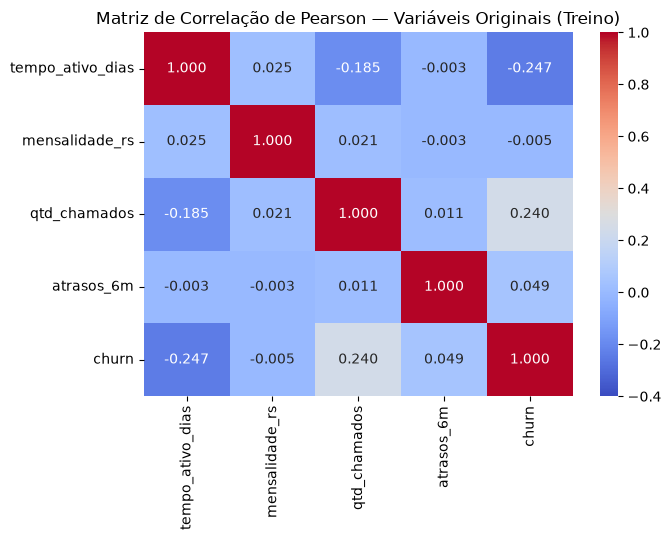

tempo_ativo_dias   -0.246679
qtd_chamados        0.240436
atrasos_6m          0.048655
mensalidade_rs     -0.004591
Name: churn, dtype: float64


In [29]:
correlacao = treino_tratado[numericas + ['churn']].corr(method='pearson')

plt.figure(figsize=(7, 5.5))
sns.heatmap(correlacao, annot=True, fmt='.3f', cmap='coolwarm', vmin=-0.4, vmax=1.0)
plt.title('Matriz de Correlação de Pearson — Variáveis Originais (Treino)')
plt.tight_layout()
plt.show()

print(correlacao['churn'].drop('churn').sort_values(key=abs, ascending=False))

#### Combo Risco Triplo (tempo <= 18 meses, chamados >= 2 e atrasos >= 1)

In [30]:
combo = ((treino_tratado['tempo_ativo_dias'] <= 18 * 30) &
         (treino_tratado['qtd_chamados'] >= 2) &
         (treino_tratado['atrasos_6m'] >= 1)).astype(int)

print(f"Clientes no combo: {combo.sum()} ({combo.mean():.2%})")
print(f"Churn dentro do combo: {treino_tratado.loc[combo == 1, 'churn'].mean():.2%}")
print(f"Churn fora do combo: {treino_tratado.loc[combo == 0, 'churn'].mean():.2%}")
print(f"Correlação com churn: {combo.corr(treino_tratado['churn']):.3f}")

Clientes no combo: 539 (15.43%)
Churn dentro do combo: 63.27%
Churn fora do combo: 30.43%
Correlação com churn: 0.248


**Conclusões da exploração:** *(preencher com a análise da equipe)*

### Padronização das variáveis numéricas

O StandardScaler aprende a média e o desvio padrão somente no treino. O teste é apenas transformado com esses valores.

In [31]:
scaler = StandardScaler()
scaler.fit(X_treino[numericas])

X_treino[numericas] = scaler.transform(X_treino[numericas])
X_teste[numericas] = scaler.transform(X_teste[numericas])

display(pd.DataFrame({'média (treino)': scaler.mean_, 'desvio (treino)': scaler.scale_}, index=numericas).round(3))

,média (treino),desvio (treino)
tempo_ativo_dias,750.228,468.096
mensalidade_rs,88.822,237.974
qtd_chamados,1.713,1.427
atrasos_6m,1.227,4.179


### Contrato de dados

Regras de validação da Aula 2: problemas críticos bloqueiam o pipeline, os demais geram alerta.

In [32]:
def validar_contrato(base, nome):
    print(f"Contrato de dados - {nome}")
    # Validação de esquema (bloqueio)
    obrigatorias = ['id_cliente', 'data_corte'] + numericas + binarias_x + categoricas + ['churn']
    faltando = [c for c in obrigatorias if c not in base.columns]
    if faltando:
        raise Exception(f"BLOQUEIO: colunas obrigatórias ausentes {faltando}")
    # Validação do alvo (bloqueio)
    if base['churn'].isna().any() or not base['churn'].isin([0, 1]).all():
        raise Exception("BLOQUEIO: churn com valor faltante ou fora de {0, 1}")
    # Taxa de ausência da mensalidade (alerta acima de 20%)
    taxa = base['mensalidade_rs'].isna().mean()
    print(f"  {'ALERTA' if taxa > 0.20 else 'OK'}: mensalidade faltante = {taxa:.2%}")
    # Domínio categórico (alerta)
    for coluna, dominio in dominios.items():
        fora = (base[coluna].notna() & ~base[coluna].isin(dominio)).sum()
        print(f"  {'ALERTA' if fora else 'OK'}: valores fora do padrão em {coluna} = {fora}")
    # Duplicatas de chave (alerta)
    duplicados = base.duplicated(subset=['id_cliente', 'data_corte']).sum()
    print(f"  {'ALERTA' if duplicados else 'OK'}: chaves duplicadas = {duplicados}")

validar_contrato(treino, 'treino')
validar_contrato(teste, 'teste')

Contrato de dados - treino
  OK: mensalidade faltante = 2.43%
  ALERTA: valores fora do padrão em tipo_contrato = 12
  OK: valores fora do padrão em forma_pagamento = 0
  OK: chaves duplicadas = 0
Contrato de dados - teste
  OK: mensalidade faltante = 2.34%
  ALERTA: valores fora do padrão em tipo_contrato = 3
  OK: valores fora do padrão em forma_pagamento = 0
  OK: chaves duplicadas = 0


### Exportando a base transformada

In [33]:
treino_tratado.to_csv("base_churn_treino_transformada.csv")
teste.to_csv("base_churn_teste_transformada.csv")

display(treino_tratado)

,tempo_ativo_dias,mensalidade_rs,qtd_chamados,atrasos_6m,fibra_optica,debito_automatico,tipo_contrato_Anual,tipo_contrato_Bienal,tipo_contrato_Bienal,tipo_contrato_Mensal,forma_pagamento_Boleto,forma_pagamento_Cartão,forma_pagamento_Pix,churn
0,639.0,73.33,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0
1,608.0,69.40,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0
2,457.0,98.76,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1
3,730.0,92.37,2.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0
4,1553.0,58.78,2.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3488,914.0,80.96,3.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0
3489,1553.0,90.32,2.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1
3490,608.0,117.97,1.0,2.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1
3491,1158.0,57.72,3.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0
